In [10]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

import math, time, copy
import matplotlib.pyplot as plt


seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [11]:
# --- load & basic columns ---
df = pd.read_csv("data.csv")
FEATURE_COLS = [c for c in df.columns if c != "Strength"]
TARGET_COL = "Strength"
df.columns

Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Strength'],
      dtype='str')

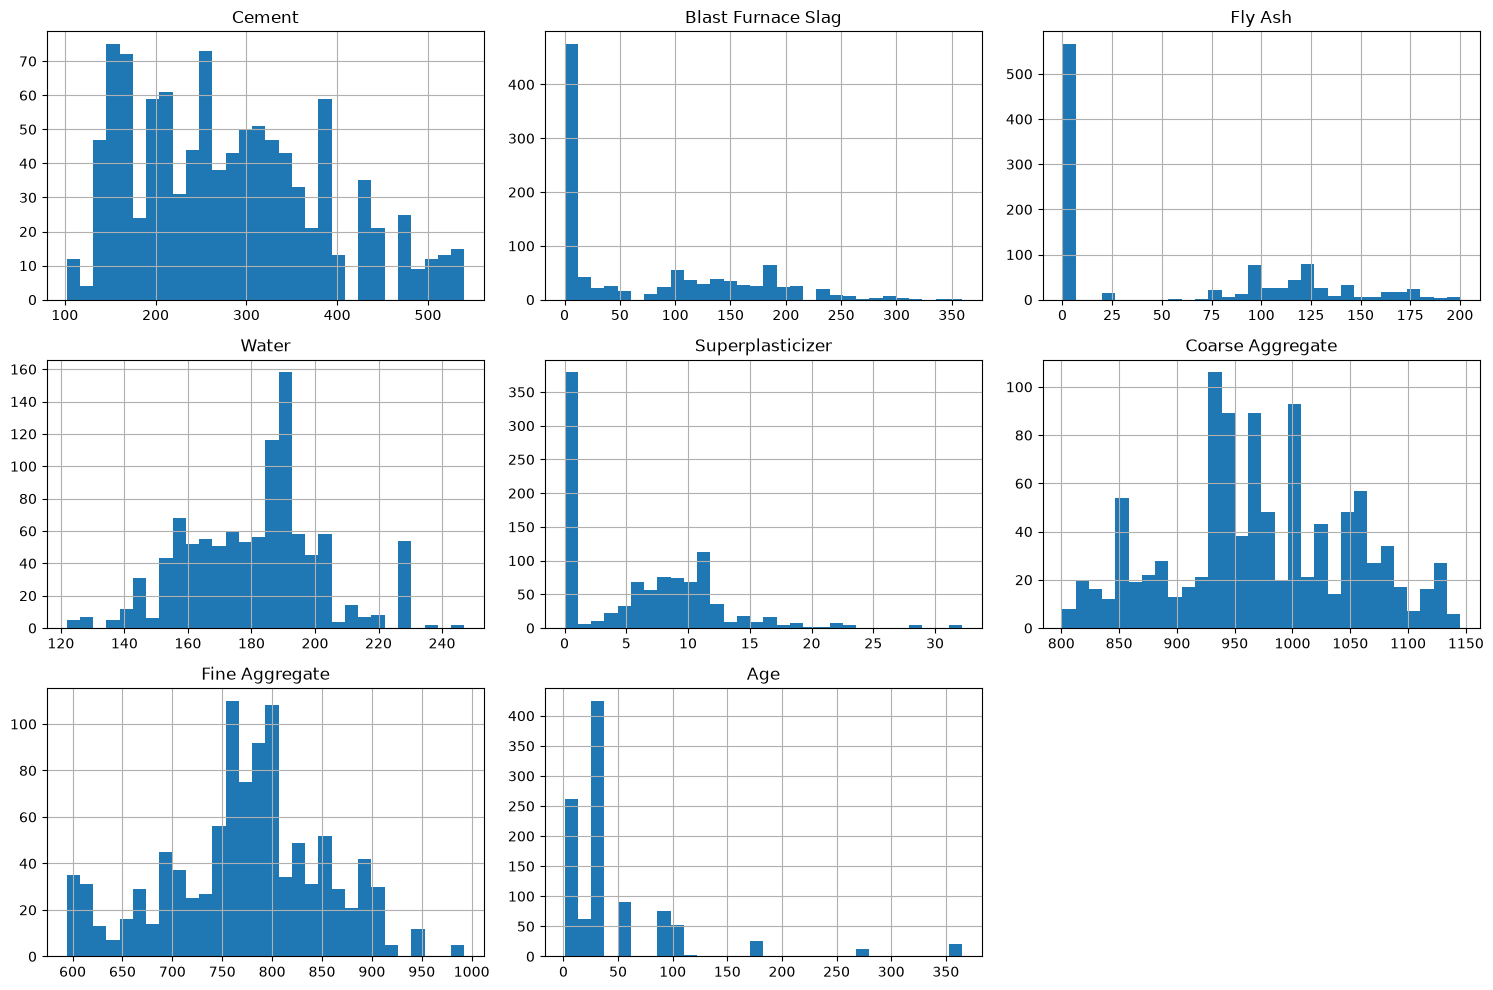

In [23]:
# ------ TODO: Visualize Distributions ------
df[FEATURE_COLS].hist(bins=30, figsize=(15,10))
plt.tight_layout()
plt.savefig("task1_features.png")
plt.show()

# ------ end TODO ------

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

# ------ TODO: Preprocess data ------
x = df[FEATURE_COLS].values
y = df[TARGET_COL].values
#60% train 40% rest
x_train, x_temp, y_train, y_temp = train_test_split(x,y,test_size=(0.4),random_state=seed)
#from the 40% -> 50% val, 50% test
x_val, x_test, y_val, y_test = train_test_split(x_temp,y_temp,test_size=(0.5),random_state=seed)

scaler = StandardScaler()
# scaler fit only to train data
x_train_scaled = scaler.fit_transform(x_train)
# val and test only transform
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

#transform for pytorch

x_train_tensor = torch.tensor(x_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)

x_val_tensor = torch.tensor(x_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)

x_test_tensor = torch.tensor(x_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

#create datasets

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

batch_size = 32


train_loader = DataLoader(train_dataset, batch_size, shuffle= True)
val_loader   = DataLoader(val_dataset, batch_size, shuffle= True)
test_loader  = DataLoader(test_dataset, batch_size, shuffle= True)
# ------ end TODO ------

In [18]:
class YouModel(nn.Module):  # rename however you like
    def __init__(self, input_dim, hidden_dims, activation=nn.ReLU):
        super().__init__()
        # ------ TODO: Define Layers ------
        layers = []
        current_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim,hidden_dim))
            layers.append(activation())
            current_dim = hidden_dim
        
        layers.append(nn.Linear(current_dim,1))
        self.layers = nn.Sequential(*layers)
        # ------ end TODO ------
        pass
        
    def forward(self, x):
        # ------ TODO: Define Forward Function ------
        return self.layers(x)
        # ------ end TODO ------
        pass

## Helper functions for gradient tracking
Following the official [PyTorch Tutorial](https://docs.pytorch.org/tutorials/intermediate/visualizing_gradients_tutorial.html), the following functions help you with gradient analysis.

They add a _hook_ to the backward pass, which stores the gradients of each layer in a list. This will be done at each backward pass, so once per mini-batch. The function `get_grads_per_layer(grads)`averages



In [15]:
def hook_forward(module_name, grads, hook_backward):
    def hook(module, args, output):
        """Forward pass hook which attaches backward pass hooks to intermediate tensors"""
        if not torch.is_grad_enabled():
            return
        output.register_hook(hook_backward(module_name, grads))
    return hook

def hook_backward(module_name, grads):
    def hook(grad):
        """Backward pass hook which appends gradients"""
        grads[module_name].append(grad.detach().abs().mean().cpu())
    return hook

def register_gradient_hook(model, hook_forward, hook_backward):
    """Register forward pass hook (which registers a backward hook) to model outputs

    Returns:
        - layers: a dict with keys as layer/module and values as layer/module names
                  e.g. layers[nn.Conv2d] = layer1.0.conv1
        - grads: a list of tuples with module name and tensor output gradient
                 e.g. grads[0] == (layer1.0.conv1, tensor.Torch(...))
    """
    from collections import defaultdict
    layers = dict()
    grads = defaultdict(list)
    for name, layer in model.named_modules():
        # skip containers / wrappers; only hook leaves
        if not any(layer.children()):
            layers[layer] = name
            layer.register_forward_hook(hook_forward(name, grads, hook_backward))
    return layers, grads


def aggregate_grads_epoch(grads_dict):
    """
    Combine all (mean|grad|) scalars collected across the entire epoch
    into a single scalar per layer.
    """
    averaged = []
    for layer_name, vals in grads_dict.items():
        if len(vals) == 0:
            continue
        # vals is a list of 0-D CPU tensors
        avg = torch.stack(vals).mean().item()  # float for easy logging
        averaged.append({"layer": layer_name, "grad": avg})
    return averaged

In [16]:

# --- device ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# how often to print per-epoch progress
log_every = 1 


# helper function to automate optimizer creation
def make_optimizer(name, params, lr, momentum=0.0):
    name = name.lower()
    if name in ("sgd",):
        return torch.optim.SGD(params, lr=lr, momentum=0.0)
    if name in ("sgd_momentum", "momentum", "sgdm", "sgd"):
        return torch.optim.SGD(params, lr=lr, momentum=momentum)
    if name in ("adam",):
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f"Unknown optimizer: {name}")


# --- training helper ---
def train_one_model(input_dim, hidden, lr, max_epochs, 
                    train_loader, val_loader, 
                    optimizer_name="adam", momentum = 0.9, verbose=True):

    # ------ TODO: create model, criterion and optimizer ------
    model = YouModel(input_dim,hidden).to(device)
    criterion = nn.MSELoss()
    optimizer = make_optimizer(optimizer_name,model.parameters(), lr, momentum)

    # ------ end TODO ------

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "gradients": [],
    }
    _, grads = register_gradient_hook(model, hook_forward, hook_backward)


    best_state = None
    best_val = math.inf
    t0 = time.time()

    for epoch in range(1, max_epochs + 1):
        # train
        model.train()
        running_train = 0.0
        n_train_batches = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            
            grads.clear()   # this is only for the gradient tracking

            # ------ TODO: execute the main update steps ------
            # Don't forget to reset the gradient! 
            
            optimizer.zero_grad()
            preds = model(xb)

            loss = criterion(preds, yb)

            loss.backward()
            optimizer.step()   
            

            # ------ end TODO ------

            running_train += loss.item()
            n_train_batches += 1


        average_grads = aggregate_grads_epoch(grads)

        for k in list(grads.keys()):
            grads[k].clear()

        train_loss = running_train / max(1, n_train_batches)

        # validate
        model.eval()
        running_val = 0.0
        n_val_batches = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)
                running_val += criterion(model(xb), yb).item()
                n_val_batches += 1

        val_loss = running_val / max(1, n_val_batches)

        # history tracks variables at each epoch
        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["gradients"].append(average_grads)

        # intermediate outputs
        if verbose and (epoch % log_every == 0 or epoch == 1 or epoch == max_epochs):
            print(f"[{hidden} | lr={lr:.0e} | epoch {epoch:>3}/{max_epochs}] "
                  f"train={train_loss:.6f}  val={val_loss:.6f}")

        # track best (by val)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

    elapsed = time.time() - t0
    # restore best weights
    if best_state is not None:
        model.load_state_dict(best_state)

    # ------ TODO: calculate number of parameters ------
    num_params = sum(p.numel() for p in model.parameters()) 
    # ------ end TODO ------
    
    # The result returns all the information we might need later. 
    # ------ TODO: have a look at all the of them, add more if necessary ------
    result = {
        "hidden": hidden,
        "lr": lr,
        "max_epochs": max_epochs,
        "optimizer": optimizer_name,
        "momentum": float(momentum),
        "best_val_loss": float(best_val),
        "final_train_loss": float(history["train_loss"][-1]),
        "final_val_loss": float(history["val_loss"][-1]),
        "n_epochs_ran": max_epochs,
        "history": history,
        "train_time_sec": elapsed,
        "model": model,
        "parameters": num_params
    }
    # ------ end todo ------
    return result

Using device: cpu


In [19]:
# --- run grid search ---
from itertools import product

# ------ TODO: define these values. Create copies for different experiments/tasks ------
param_grid_exp1 = {
    "lr":         [0.01, 0.001],
    "hidden":     [[32], [64, 32], [128, 64, 32]],
    "max_epochs": [50],
    "optimizer":  ["adam"],
    "momentum":   [0.0],   # only used when optimizer == "sgd_momentum"
}

input_dim = 8
# ------ end TODO ------

def run_grid_search(param_grid):
    results = []
    print("\n=== GRID SEARCH START ===")
    # ------ TODO: adjust the parameters try if necessary ------
    for optimizer_name in param_grid["optimizer"]:
        # decide which momenta to test
        if optimizer_name == "sgd_momentum":
            momenta = param_grid["momentum"]
        else:
            momenta = [0.0]   # placeholder (not used)

        for lr, hidden, max_epochs, momentum in product(
            param_grid["lr"],
            param_grid["hidden"],
            param_grid["max_epochs"],
            momenta
        ):
            print(f"\n>>> Config: opt={optimizer_name}, hidden={hidden}, lr={lr}, mom={momentum}, epochs={max_epochs}")

            out = train_one_model(
                input_dim=input_dim,
                hidden=hidden,
                lr=lr,
                max_epochs=max_epochs,
                train_loader=train_loader,
                val_loader=val_loader,
                optimizer_name=optimizer_name,
                momentum=momentum,
                verbose=True
            )
            
    # ------ end TODO ------
            results.append(out)
    print("\n=== GRID SEARCH DONE ===")
    
    return results

# ------ TODO: change/duplicate for your experiments ------
results = run_grid_search(param_grid_exp1)
# ------ end TODO ------


=== GRID SEARCH START ===

>>> Config: opt=adam, hidden=[32], lr=0.01, mom=0.0, epochs=50
[[32] | lr=1e-02 | epoch   1/50] train=1515.639185  val=1407.670244
[[32] | lr=1e-02 | epoch   2/50] train=1289.705594  val=1015.898873
[[32] | lr=1e-02 | epoch   3/50] train=810.737071  val=481.980713
[[32] | lr=1e-02 | epoch   4/50] train=356.380488  val=213.817610
[[32] | lr=1e-02 | epoch   5/50] train=199.371327  val=207.761496
[[32] | lr=1e-02 | epoch   6/50] train=168.027799  val=173.074021
[[32] | lr=1e-02 | epoch   7/50] train=155.665749  val=161.543896
[[32] | lr=1e-02 | epoch   8/50] train=143.967309  val=155.125268
[[32] | lr=1e-02 | epoch   9/50] train=140.736457  val=155.363052
[[32] | lr=1e-02 | epoch  10/50] train=135.157557  val=148.752446
[[32] | lr=1e-02 | epoch  11/50] train=133.838288  val=140.460812
[[32] | lr=1e-02 | epoch  12/50] train=131.870824  val=137.228020
[[32] | lr=1e-02 | epoch  13/50] train=128.537116  val=131.881784
[[32] | lr=1e-02 | epoch  14/50] train=131.8288

In [20]:
def show_results(results):
    # ------ TODO: add different parameters / change formatting when necessary ------
    fmt = {
        "lr": "{:.1e}",
        "momentum": "{:.2f}",
        "final_train_loss": "{:.2f}",
        "final_val_loss": "{:.2f}",
        "best_val_loss": "{:.2f}",
        "train_time_sec": "{:.2f}",
        "parameters": "{:,}",
    }

    def _fmt_hidden(h): return "-".join(map(str, h))

    # Build summary dataframe
    df = pd.DataFrame([{
        "optimizer": r.get("optimizer", "unknown"),
        "momentum": r.get("momentum", 0.0),
        "hidden": _fmt_hidden(r["hidden"]),
        "lr": r["lr"],
        "epochs": r["max_epochs"],
        "final_train_loss": r["final_train_loss"],
        "final_val_loss": r["final_val_loss"],
        "best_val_loss": r["best_val_loss"],
        "train_time_sec": round(r["train_time_sec"], 2),
        "parameters": r["parameters"],
    } for r in results]).sort_values("best_val_loss").reset_index(drop=True)
    
    # ------ end TODO ------


    # Print results (formatted like notebook view)
    print("\n=== RESULTS (sorted by best val loss) ===")
    print(df.to_string(
        index=False,
        formatters={k: (lambda x, f=f: f.format(x)) for k, f in fmt.items() if k in df.columns}
    ))

    # Pretty notebook display (same formatting)
    try:
        from IPython.display import display
        display(df.style.format(fmt))
    except Exception:
        pass

    # return df     # can be used to show an interactive Jupyter table

# ------ TODO: change/duplicate for your experiments ------
show_results(results)
# ------ end TODO ------


=== RESULTS (sorted by best val loss) ===
optimizer momentum    hidden      lr  epochs final_train_loss final_val_loss best_val_loss train_time_sec parameters
     adam     0.00 128-64-32 1.0e-02      50            27.05          28.53         25.35           6.56     11,521
     adam     0.00     64-32 1.0e-02      50            26.09          29.38         28.79           2.91      2,689
     adam     0.00 128-64-32 1.0e-03      50            38.13          48.55         47.00           5.90     11,521
     adam     0.00        32 1.0e-02      50           102.34         108.26        106.54           2.27        321
     adam     0.00     64-32 1.0e-03      50           100.38         113.03        113.03           1.84      2,689
     adam     0.00        32 1.0e-03      50           162.98         184.73        177.17           1.85        321


,optimizer,momentum,hidden,lr,epochs,final_train_loss,final_val_loss,best_val_loss,train_time_sec,parameters
0,adam,0.00,128-64-32,1.0e-02,50,27.05,28.53,25.35,6.56,"11,521"
1,adam,0.00,64-32,1.0e-02,50,26.09,29.38,28.79,2.91,"2,689"
2,adam,0.00,128-64-32,1.0e-03,50,38.13,48.55,47.00,5.90,"11,521"
3,adam,0.00,32,1.0e-02,50,102.34,108.26,106.54,2.27,321
4,adam,0.00,64-32,1.0e-03,50,100.38,113.03,113.03,1.84,"2,689"
5,adam,0.00,32,1.0e-03,50,162.98,184.73,177.17,1.85,321


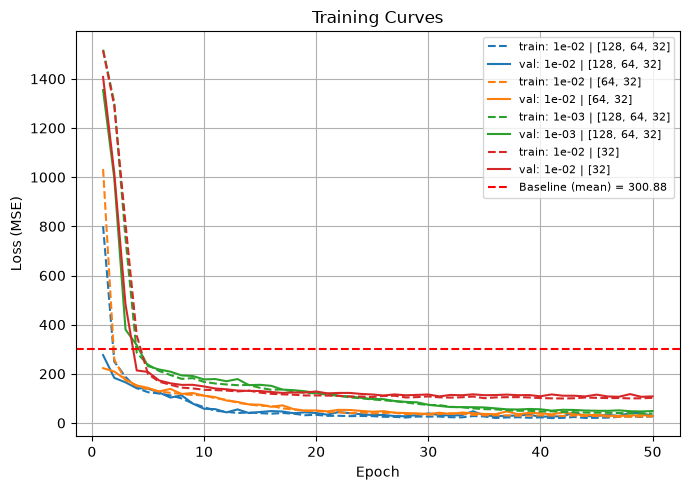

In [21]:
def plot_training_curves(results, baseline=True, optimizer_labels=False):
    plt.figure(figsize=(7,5))

    # Get color cycle
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for i, r in enumerate(results):
        h = r["history"]
        if optimizer_labels:
            label = f"{r['optimizer']} | {r['momentum']:.2f}"
        else:
            label = f"{r['lr']:.0e} | {r['hidden']}"
        
        color = color_cycle[i % len(color_cycle)]  # consistent color per config

        plt.plot(h["epoch"], h["train_loss"], '--', color=color, label=f"train: {label}")
        plt.plot(h["epoch"], h["val_loss"], '-', color=color, label=f"val: {label}")

    # --- compute and add a baseline MSE (predict mean of y_train) ---
    if baseline:
        y_train_all = []
        y_val_all = []
        for _, yb in train_loader:
            y_train_all.append(yb.numpy())
        for _, yb in val_loader:
            y_val_all.append(yb.numpy())
        y_train_all = np.concatenate(y_train_all).squeeze()
        y_val_all = np.concatenate(y_val_all).squeeze()

        baseline_pred = np.full_like(y_val_all, y_train_all.mean())
        baseline_mse = np.mean((y_val_all - baseline_pred) ** 2)

        plt.axhline(baseline_mse, color="red", linestyle="--", lw=1.5, label=f"Baseline (mean) = {baseline_mse:.2f}")

    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE)")
    plt.title("Training Curves")
    plt.legend(fontsize=8)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ------ TODO: change/duplicate for your experiments ------
top_n = min(4, len(results))
top_results = sorted(results, key=lambda r: r["best_val_loss"])[:top_n]
plot_training_curves(top_results)
# ------ end TODO ------

In [ ]:
def plot_scheduler_lr(name, scheduler, num_epochs=50):
    lrs = []
    for _ in range(num_epochs):
        lrs.append(scheduler.get_last_lr())
        scheduler.step()

    plt.title(name)
    plt.plot(lrs)
    plt.xlabel('Epoch')
    plt.ylabel('Learning Rate')
    plt.show()
    
# ------ TODO: implement for your schedulers ------
optimizer = ...
scheduler = ...
plot_scheduler_lr("Title", scheduler)
# ------ end TODO ------

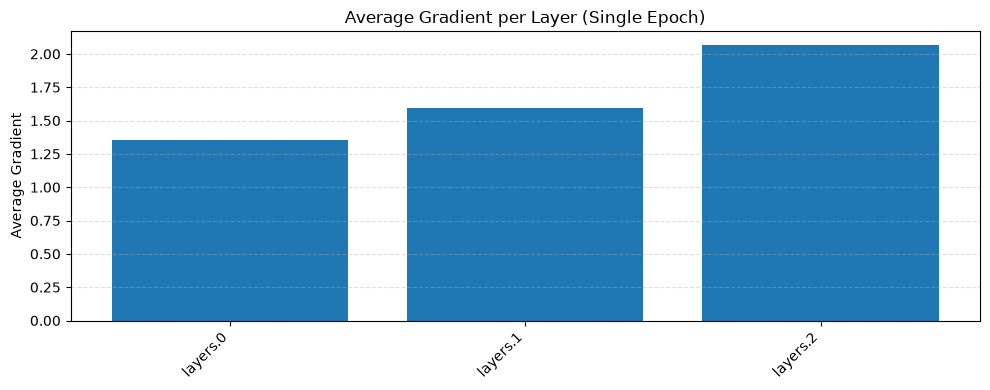

In [22]:
def plot_gradients(gradients, epoch=None,  max_xticks=20):
    if epoch is not None:
        gradients=gradients[epoch]
    
    # Filter out the activation layer
    filtered = [d for d in gradients if d['layer'] != 'activation']

    # Sort: numeric layers first, then 'out'
    def sort_key(item):
        name = item['layer']
        if name.startswith('layers.'):
            try:
                return int(name.split('.')[1])
            except ValueError:
                return -1
        elif name == 'out':
            return 9999  # push to right
        else:
            return -1

    filtered.sort(key=sort_key)

    # Extract for plotting
    layers = [d['layer'] for d in filtered]
    grads = [d['grad'].item() if torch.is_tensor(d['grad']) else float(d['grad']) for d in filtered]

    # Create plot
    plt.figure(figsize=(10, 4))
    plt.bar(range(len(layers)), grads, width=0.8)
    plt.ylabel('Average Gradient')
    plt.title('Average Gradient per Layer (Single Epoch)')
    plt.grid(True, axis='y', linestyle='--', alpha=0.4)

    # Handle many layers: only show up to `max_xticks` labels
    n_layers = len(layers)
    if n_layers > max_xticks:
        step = max(1, n_layers // max_xticks)
        tick_positions = list(range(0, n_layers, step))
        tick_labels = [layers[i] for i in tick_positions]
    else:
        tick_positions = range(n_layers)
        tick_labels = layers

    plt.xticks(tick_positions, tick_labels, rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# ------ TODO: change/duplicate for your experiments ------
plot_gradients(results[0]["history"]["gradients"], -1)
# ------ end TODO ------

In [ ]:

def iter_linear_layers(model):
    for i, layer in enumerate(model.layers):
        yield f"hidden_{i}", layer
    yield "out", model.out

# --- Heatmaps with sensible scaling ---
def plot_weight_heatmaps(model, mode="robust", q=99.5, same_scale=False):
    """
    mode: 'robust' uses symmetric percentile range per layer.
          'std'    uses k * std per layer (good for outlier robustness).
          'auto'   uses per-layer min/max (can be skewed by outliers).
    q: percentile (for 'robust'), e.g. 99.5 -> clip to ±99.5th percentile of |W|.
    same_scale: if True, use one global scale across all layers (computed from chosen mode).
    """
    stats = []
    Ws = []
    names = []
    with torch.no_grad():
        for name, layer in iter_linear_layers(model):
            W = layer.weight.detach().float().cpu().numpy()
            Ws.append(W); names.append(name)
            absW = np.abs(W)
            if mode == "robust":
                v = np.percentile(absW, q)
            elif mode == "std":
                v = absW.std() * 3.0
            elif mode == "auto":
                v = absW.max()
            else:
                raise ValueError("mode must be robust|std|auto")
            stats.append(max(v, 1e-8))

    if same_scale:
        vmax = float(max(stats))
        vmins = [-vmax]*len(Ws); vmaxs = [vmax]*len(Ws)
    else:
        vmins = [-v for v in stats]; vmaxs = stats

    n = len(Ws)
    fig, axes = plt.subplots(1, n, figsize=(4.8*n, 4))
    if n == 1: axes = [axes]
    for ax, W, name, vmin, vmax in zip(axes, Ws, names, vmins, vmaxs):
        im = ax.imshow(W, vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest")
        ax.set_title(f"{name}: {W.shape[0]}×{W.shape[1]}")
        ax.set_xlabel("in"); ax.set_ylabel("out")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.suptitle(f"Weight heatmaps (mode={mode}, same_scale={same_scale})", y=1.02)
    fig.tight_layout()

# --- Bias visualizations (1-D vectors) ---
def plot_bias_histograms(model, bins=80):
    """Plot histograms of all linear layer biases."""
    with torch.no_grad():
        layers = list(iter_linear_layers(model))
        fig, axes = plt.subplots(len(layers), 1, figsize=(8, 2.5 * len(layers)))
        if len(layers) == 1:
            axes = [axes]

        for ax, (name, layer) in zip(axes, layers):
            if layer.bias is None:
                ax.set_title(f"{name}: no bias")
                ax.axis("off")
                continue

            b = layer.bias.detach().float().cpu().numpy()
            ax.hist(b, bins=bins, density=True)
            ax.set_title(f"{name} bias (mean={b.mean():.3g}, std={b.std():.3g})")
            ax.set_xlabel("bias value")
            ax.set_ylabel("density")

        fig.tight_layout()

def plot_weight_histograms(model, bins=80):
    with torch.no_grad():
        n = sum(1 for _ in iter_linear_layers(model))
        fig, axes = plt.subplots(n, 1, figsize=(8, 2.5*n))
        if n == 1: axes = [axes]
        for ax, (name, layer) in zip(axes, iter_linear_layers(model)):
            w = layer.weight.detach().float().cpu().flatten().numpy()
            ax.hist(w, bins=bins, density=True)
            ax.set_title(f"Weight distribution - {name} (mean={w.mean():.3g}, std={w.std():.3g})")
            ax.set_xlabel("weight"); ax.set_ylabel("density")
        fig.tight_layout()


# ------ TODO: change/duplicate for your experiments ------
model = ...
plot_weight_histograms(model)
plot_weight_heatmaps(model, mode="robust", q=99.5, same_scale=False)  # extra parameters to make visualiziation better. Feel free to adapt/try without
plot_bias_histograms(model)
# ------ end TODO ------

In [ ]:
def scatterplot(results):
    # pick the best model from your grid search results
    best = min(results, key=lambda r: r["best_val_loss"])
    best_model = best["model"].eval()

    def preds_and_targets(loader, model, device):
        ys, yhats = [], []
        with torch.no_grad():
            for xb, yb in loader:
                xb = xb.to(device)
                yb = yb.to(device)
                phat = model(xb)
                ys.append(yb.detach().cpu().numpy())
                yhats.append(phat.detach().cpu().numpy())
        y  = np.concatenate(ys, axis=0).squeeze()
        yhat = np.concatenate(yhats, axis=0).squeeze()
        return y, yhat

    y_tr, yhat_tr = preds_and_targets(train_loader, best_model, device)
    y_va, yhat_va = preds_and_targets(val_loader,   best_model, device)


    mn = float(min(y_tr.min(), y_va.min(), yhat_tr.min(), yhat_va.min()))
    mx = float(max(y_tr.max(), y_va.max(), yhat_tr.max(), yhat_va.max()))

    plt.figure()
    plt.scatter(y_tr, yhat_tr, s=12, alpha=0.6, label="Train")
    plt.scatter(y_va, yhat_va, s=12, alpha=0.6, label="Val")
    plt.plot([mn, mx], [mn, mx], lw=1, linestyle="--", color="black")  # y = x reference
    plt.xlabel("True")
    plt.ylabel("Predicted")
    plt.legend()
    plt.title(f"True vs Predicted (best val loss = {best['best_val_loss']:.6f})")
    plt.tight_layout()
    plt.show()

# ------ TODO: change/duplicate for your experiments ------
scatterplot(results)
# ------ end TODO ------